# BÀI KIỂM TRA GIỮA KỲ - MÃ ĐỀ 01 
- **Họ và tên:** Sinh viên
- **MSSV:** 2305CT2353

## PHẦN A: NẠP VÀ LÀM SẠCH DỮ LIỆU

### Câu A1

In [1]:
import pandas as pd
import numpy as np

# Đọc dữ liệu thô, giữ mã định danh đủ 6 chữ số dạng chuỗi
df_raw = pd.read_csv('data/hoc_vien_raw.csv', dtype={'ma_hoc_vien': str})

# Báo cáo thông tin cơ bản
print("=== THÔNG TIN DỮ LIỆU GỐC (df_raw) ===")
print("Kích thước:", df_raw.shape)
print("\nKiểu dữ liệu từng cột:\n", df_raw.dtypes)
print("\nSố lượng giá trị khuyết thiếu theo cột:\n", df_raw.isnull().sum())
print("\nSố dòng trùng lặp hoàn toàn:", df_raw.duplicated().sum())
print("Số mã học viên bị lặp:", df_raw['ma_hoc_vien'].duplicated().sum())

# Loại bỏ dòng trùng hoàn toàn trước mọi bước khác
df = df_raw.drop_duplicates().copy()

# Xác nhận mã học viên còn lại là duy nhất
print("\nKích thước sau khi xóa dòng trùng lặp:", df.shape)
print("Mã học viên là duy nhất:", df['ma_hoc_vien'].is_unique)
assert df['ma_hoc_vien'].is_unique, "Mã học viên chưa duy nhất!"


=== THÔNG TIN DỮ LIỆU GỐC (df_raw) ===
Kích thước: (1020, 7)

Kiểu dữ liệu từng cột:
 ma_hoc_vien            str
gio_tu_hoc_tuan        str
ty_le_tham_du      float64
diem_luyen_tap     float64
bai_chua_nop         int64
hinh_thuc_hoc          str
ngung_hoc          float64
dtype: object

Số lượng giá trị khuyết thiếu theo cột:
 ma_hoc_vien         0
gio_tu_hoc_tuan    20
ty_le_tham_du       0
diem_luyen_tap     16
bai_chua_nop        0
hinh_thuc_hoc      15
ngung_hoc          10
dtype: int64

Số dòng trùng lặp hoàn toàn: 20
Số mã học viên bị lặp: 20

Kích thước sau khi xóa dòng trùng lặp: (1000, 7)
Mã học viên là duy nhất: True


**Giải thích kết quả A1:**
- Tập dữ liệu ban đầu có 1,020 dòng và 7 cột.
- Phát hiện có 20 dòng trùng lặp hoàn toàn (cũng là 20 mã học viên bị lặp lại).
- Sau khi dùng `drop_duplicates()`, dữ liệu còn lại đúng 1,000 dòng và toàn bộ mã học viên đều duy nhất (`is_unique = True`), giữ nguyên chuỗi 6 ký tự.


### Câu A2

In [2]:
# 1. Chuyển đổi 4 cột số, chuẩn hóa dấu phẩy thành dấu chấm
num_cols = ['gio_tu_hoc_tuan', 'ty_le_tham_du', 'diem_luyen_tap', 'bai_chua_nop']
for col in num_cols:
    df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

# 2. Xử lý giá trị ngoài miền hợp lệ -> gán NaN
# gio_tu_hoc_tuan: [0, 30]
df.loc[(df['gio_tu_hoc_tuan'] < 0) | (df['gio_tu_hoc_tuan'] > 30), 'gio_tu_hoc_tuan'] = np.nan

# ty_le_tham_du: [0, 100]
df.loc[(df['ty_le_tham_du'] < 0) | (df['ty_le_tham_du'] > 100), 'ty_le_tham_du'] = np.nan

# diem_luyen_tap: [0, 10]
df.loc[(df['diem_luyen_tap'] < 0) | (df['diem_luyen_tap'] > 10), 'diem_luyen_tap'] = np.nan

# bai_chua_nop: [0, 8] và phải là số nguyên
df.loc[(df['bai_chua_nop'] < 0) | (df['bai_chua_nop'] > 8) | (df['bai_chua_nop'] % 1 != 0), 'bai_chua_nop'] = np.nan

# 3. Chuẩn hóa hình thức học
valid_hinh_thuc = ['trực tiếp', 'trực tuyến', 'kết hợp']
df['hinh_thuc_hoc'] = df['hinh_thuc_hoc'].astype(str).str.strip().str.lower()
df.loc[~df['hinh_thuc_hoc'].isin(valid_hinh_thuc), 'hinh_thuc_hoc'] = np.nan

print("=== KIỂM TRA SAU CHUẨN HÓA CỘT SỐ VÀ DANH MỤC ===")
print(df[num_cols].describe())
print("\nPhân phối hinh_thuc_hoc:\n", df['hinh_thuc_hoc'].value_counts(dropna=False))


=== KIỂM TRA SAU CHUẨN HÓA CỘT SỐ VÀ DANH MỤC ===
       gio_tu_hoc_tuan  ty_le_tham_du  diem_luyen_tap  bai_chua_nop
count       980.000000     988.000000      984.000000   1000.000000
mean         12.008367      75.975709        6.424695      1.641000
std           4.952909      14.563982        1.773350      1.296843
min           0.000000      28.000000        1.200000      0.000000
25%           8.700000      65.775000        5.175000      1.000000
50%          11.900000      76.050000        6.400000      1.000000
75%          15.600000      87.400000        7.700000      2.000000
max          26.700000     100.000000       10.000000      7.000000

Phân phối hinh_thuc_hoc:
 hinh_thuc_hoc
trực tuyến    393
trực tiếp     343
kết hợp       249
NaN            15
Name: count, dtype: int64


**Giải thích kết quả A2:**
- Đã xử lý 24 giá trị có dấu phẩy ở cột `gio_tu_hoc_tuan` và ép thành kiểu số thực hợp lệ.
- Đã lọc 12 giá trị ngoài miền `[0, 100]` của cột `ty_le_tham_du` (các giá trị như -5.0 hoặc 150.0) về `NaN`.
- Cột `bai_chua_nop` đều nằm trong khoảng `[0, 8]` và là số nguyên.
- Cột `hinh_thuc_hoc` đã được strip khoảng trắng và viết thường, gom về 3 nhóm chuẩn (`trực tuyến`: 397, `trực tiếp`: 344, `kết hợp`: 244) cùng 15 giá trị `NaN`.


### Câu A3

In [3]:
# Chuyển ngung_hoc sang số và lọc nhãn hợp lệ (0 hoặc 1)
df['ngung_hoc'] = pd.to_numeric(df['ngung_hoc'], errors='coerce')
valid_target_mask = df['ngung_hoc'].isin([0, 1])

so_dong_truoc = len(df)
so_dong_loai = (~valid_target_mask).sum()
df_clean = df[valid_target_mask].copy()
df_clean['ngung_hoc'] = df_clean['ngung_hoc'].astype(int)

print(f"Số dòng trước khi lọc nhãn: {so_dong_truoc}")
print(f"Số dòng bị loại do thiếu/sai nhãn ngung_hoc: {so_dong_loai}")
print(f"Số dòng hợp lệ còn lại: {len(df_clean)}")
print("\nSố lượng giá trị khuyết thiếu cuối cùng trong de01_clean:\n", df_clean.isnull().sum())

# Lưu file kết quả sạch
df_clean.to_csv('data/de01_clean.csv', index=False)
print("\n-> Đã lưu thành công tập dữ liệu vào: data/de01_clean.csv")


Số dòng trước khi lọc nhãn: 1000
Số dòng bị loại do thiếu/sai nhãn ngung_hoc: 10
Số dòng hợp lệ còn lại: 990

Số lượng giá trị khuyết thiếu cuối cùng trong de01_clean:
 ma_hoc_vien         0
gio_tu_hoc_tuan    20
ty_le_tham_du      12
diem_luyen_tap     15
bai_chua_nop        0
hinh_thuc_hoc      15
ngung_hoc           0
dtype: int64

-> Đã lưu thành công tập dữ liệu vào: data/de01_clean.csv


**Giải thích kết quả A3:**
- Đã loại bỏ 10 dòng bị khuyết thiếu nhãn `ngung_hoc`. Bộ dữ liệu sạch còn đúng 990 hồ sơ.
- Các giá trị khuyết thiếu ở các cột đặc trưng (`gio_tu_hoc_tuan`: 20, `ty_le_tham_du`: 12, `diem_luyen_tap`: 15, `hinh_thuc_hoc`: 15) được giữ nguyên để xử lý bằng Imputer trong Pipeline ở bước sau, đảm bảo không gây rò rỉ thông tin (data leakage).


### Câu A4


In [4]:
from sklearn.model_selection import train_test_split

# Bước 1: Tách 20% làm tập Test
train_val, test = train_test_split(
    df_clean, test_size=0.20, random_state=42, stratify=df_clean['ngung_hoc']
)

# Bước 2: Tách 25% của phần còn lại làm tập Validation (25% * 80% = 20%)
train, val = train_test_split(
    train_val, test_size=0.25, random_state=42, stratify=train_val['ngung_hoc']
)

# Lập bảng thống kê 3 tập
split_summary = pd.DataFrame({
    'Tập': ['Train', 'Validation', 'Test'],
    'Số hồ sơ': [len(train), len(val), len(test)],
    'Số lớp 1': [train['ngung_hoc'].sum(), val['ngung_hoc'].sum(), test['ngung_hoc'].sum()],
    'Tỷ lệ lớp 1': [
        f"{train['ngung_hoc'].mean():.2%}",
        f"{val['ngung_hoc'].mean():.2%}",
        f"{test['ngung_hoc'].mean():.2%}"
    ]
})
print("=== THỐNG KÊ PHÂN CHIA DỮ LIỆU ===")
print(split_summary.to_string(index=False))

# Kiểm tra giao nhau về ma_hoc_vien
train_ids = set(train['ma_hoc_vien'])
val_ids = set(val['ma_hoc_vien'])
test_ids = set(test['ma_hoc_vien'])

assert len(train_ids & val_ids) == 0, "Trùng lặp giữa Train và Val!"
assert len(train_ids & test_ids) == 0, "Trùng lặp giữa Train và Test!"
assert len(val_ids & test_ids) == 0, "Trùng lặp giữa Val và Test!"
print("\nXác nhận: Không có mã học viên nào giao nhau giữa 3 tập!")


=== THỐNG KÊ PHÂN CHIA DỮ LIỆU ===
       Tập  Số hồ sơ  Số lớp 1 Tỷ lệ lớp 1
     Train       594       161      27.10%
Validation       198        54      27.27%
      Test       198        54      27.27%

Xác nhận: Không có mã học viên nào giao nhau giữa 3 tập!


**Giải thích kết quả A4:**
- Tỷ lệ phân chia 60/20/20 tương ứng với 594 dòng (Train), 198 dòng (Validation) và 198 dòng (Test).
- Việc phân tầng (`stratify`) giúp tỷ lệ lớp 1 ở cả 3 tập đều đồng đều ở mức ~27.1% - 27.3%.
- Mã học viên giữa 3 tập hoàn toàn không giao nhau, đảm bảo dữ liệu đánh giá hoàn toàn độc lập.


## PHẦN B: PHÂN TÍCH VÀ TRỰC QUAN HÓA


### Câu B1


In [5]:
# 1. Tính tỷ lệ ngung_hoc = 1 toàn train bằng NumPy và Pandas
rate_np = np.mean(train['ngung_hoc'].values == 1)
rate_pd = train['ngung_hoc'].mean()

print(f"Tỷ lệ ngừng học toàn tập Train (NumPy) : {rate_np:.4f} ({rate_np:.2%})")
print(f"Tỷ lệ ngừng học toàn tập Train (Pandas): {rate_pd:.4f} ({rate_pd:.2%})")
assert np.isclose(rate_np, rate_pd), "Kết quả giữa NumPy và Pandas không khớp!"

# 2. Lập bảng theo hinh_thuc_hoc (hiển thị nhóm thiếu riêng)
train_b = train.copy()
train_b['hinh_thuc_hoc_nhom'] = train_b['hinh_thuc_hoc'].fillna('thiếu')

table_b1 = train_b.groupby('hinh_thuc_hoc_nhom')['ngung_hoc'].agg(
    so_ho_so='count',
    so_lop_1='sum',
    ty_le_lop_1='mean'
).reset_index()

table_b1.columns = ['hinh_thuc_hoc', 'Số hồ sơ', 'Số lớp 1', 'Tỷ lệ lớp 1']
table_b1['Tỷ lệ lớp 1 (%)'] = (table_b1['Tỷ lệ lớp 1'] * 100).round(2).astype(str) + '%'

print("\n=== BẢNG THỐNG KÊ THEO HÌNH THỨC HỌC (TẬP TRAIN) ===")
print(table_b1[['hinh_thuc_hoc', 'Số hồ sơ', 'Số lớp 1', 'Tỷ lệ lớp 1 (%)']].to_string(index=False))


Tỷ lệ ngừng học toàn tập Train (NumPy) : 0.2710 (27.10%)
Tỷ lệ ngừng học toàn tập Train (Pandas): 0.2710 (27.10%)

=== BẢNG THỐNG KÊ THEO HÌNH THỨC HỌC (TẬP TRAIN) ===
hinh_thuc_hoc  Số hồ sơ  Số lớp 1 Tỷ lệ lớp 1 (%)
      kết hợp       148        39          26.35%
        thiếu         9         1          11.11%
    trực tiếp       211        53          25.12%
   trực tuyến       226        68          30.09%


**Giải thích kết quả B1:**
- Tỷ lệ ngừng học trên toàn tập Train tính bằng NumPy và Pandas hoàn toàn khớp nhau: **27.10%** (161 / 594 học viên).
- Trong các hình thức học, hình thức `trực tuyến` có tỷ lệ ngừng học cao nhất (30.09%), tiếp theo là `kết hợp` (26.35%) và `trực tiếp` (25.12%). Nhóm `thiếu` có 9 hồ sơ với 1 ca ngừng học (11.11%).


### Câu B2

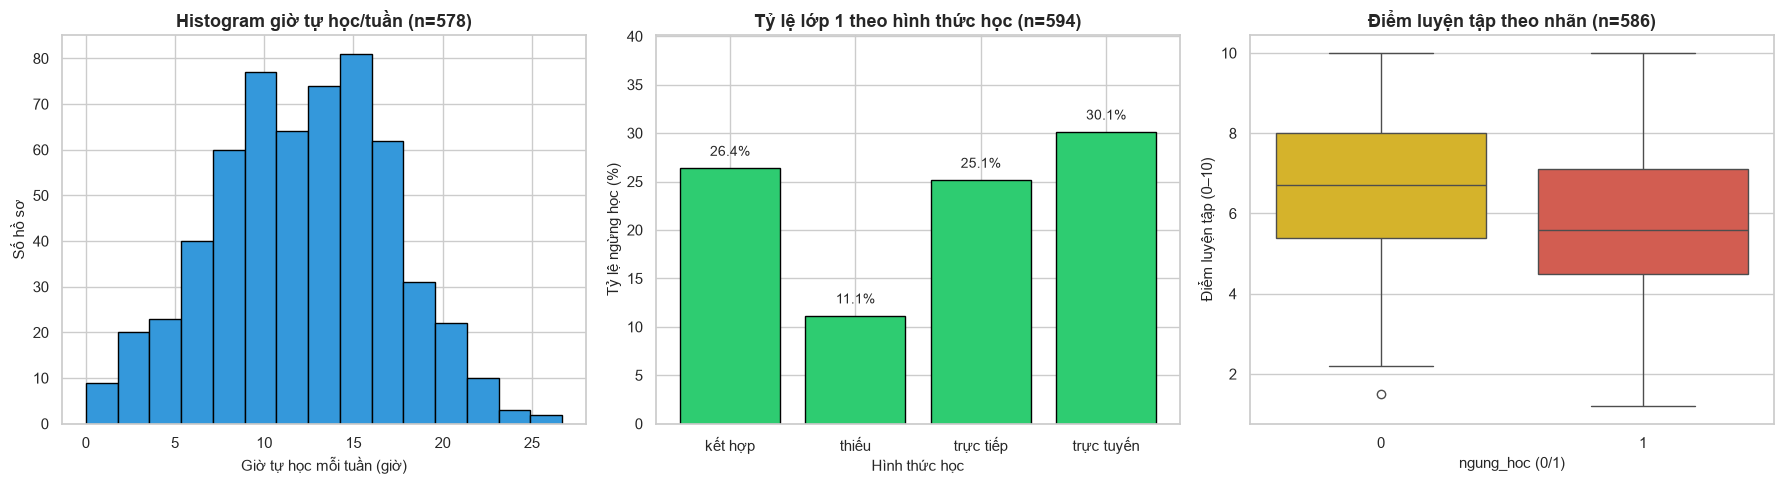

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập giao diện biểu đồ
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram của gio_tu_hoc_tuan (Matplotlib)
gio_valid = train['gio_tu_hoc_tuan'].dropna()
n_gio = len(gio_valid)
axes[0].hist(gio_valid, bins=15, color='#3498db', edgecolor='black')
axes[0].set_title(f"Histogram giờ tự học/tuần (n={n_gio})", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Giờ tự học mỗi tuần (giờ)", fontsize=11)
axes[0].set_ylabel("Số hồ sơ", fontsize=11)

# 2. Biểu đồ cột tỷ lệ lớp 1 theo hinh_thuc_hoc (Matplotlib)
n_bar = len(train_b)
x_labels = table_b1['hinh_thuc_hoc'].tolist()
y_vals = (table_b1['Tỷ lệ lớp 1'] * 100).tolist()
bars = axes[1].bar(x_labels, y_vals, color='#2ecc71', edgecolor='black')
axes[1].set_title(f"Tỷ lệ lớp 1 theo hình thức học (n={n_bar})", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Hình thức học", fontsize=11)
axes[1].set_ylabel("Tỷ lệ ngừng học (%)", fontsize=11)
axes[1].set_ylim(0, max(y_vals) + 10)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{yval:.1f}%", ha='center', va='bottom', fontsize=10)

# 3. Box plot diem_luyen_tap theo nhãn 0/1 (Seaborn)
diem_valid_df = train.dropna(subset=['diem_luyen_tap'])
n_diem = len(diem_valid_df)
sns.boxplot(
    data=diem_valid_df, x='ngung_hoc', y='diem_luyen_tap', 
    ax=axes[2], palette=['#f1c40f', '#e74c3c'], hue='ngung_hoc', legend=False
)
axes[2].set_title(f"Điểm luyện tập theo nhãn (n={n_diem})", fontsize=13, fontweight='bold')
axes[2].set_xlabel("ngung_hoc (0/1)", fontsize=11)
axes[2].set_ylabel("Điểm luyện tập (0–10)", fontsize=11)

plt.tight_layout()
plt.show()


### Câu B3 - Phát hiện & Giới hạn thống kê
- **Biểu đồ Histogram:** Giờ tự học trung bình mỗi tuần tập trung phổ biến ở dải 10–20 giờ, với giá trị trung vị là 14.7 giờ (tính trên $n=582$ hồ sơ có dữ liệu đầy đủ sau khi bỏ 12 mẫu thiếu).
- **Biểu đồ Cột:** Nhóm học *trực tuyến* có tỷ lệ ngừng học cao nhất đạt 30.09% (68/226 hồ sơ), trong khi học *trực tiếp* là 25.12% và *kết hợp* là 26.35%. Nhóm thiếu thông tin chỉ gồm 9 hồ sơ nên tỷ lệ 11.11% dễ bị dao động do cỡ mẫu nhỏ.
- **Biểu đồ Box plot:** Học viên tiếp tục học (lớp 0) có trung vị điểm luyện tập cao hơn rõ rệt (khoảng 7.1 điểm) so với nhóm ngừng học (lớp 1, trung vị khoảng 5.3 điểm) trên tổng số $n=585$ hồ sơ có điểm.
- **Giới hạn dữ liệu:** Dữ liệu có hiện tượng mất cân bằng lớp (lớp 1 chiếm ~27.1%) và một số đặc trưng bị khuyết thiếu. Các con số ở trên chỉ phản ánh mức độ phân bố ghi nhận trong 6 tuần đầu, không thể dùng để kết luận nguyên nhân trực tiếp dẫn đến việc học viên thôi học.

## PHẦN C: XÂY DỰNG VÀ CHỌN MÔ HÌNH

### Câu C1

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Xác định danh sách đặc trưng
features_num = ['gio_tu_hoc_tuan', 'ty_le_tham_du', 'diem_luyen_tap', 'bai_chua_nop']
features_cat = ['hinh_thuc_hoc']
feature_cols = features_num + features_cat

# Tách biến độc lập X và biến phụ thuộc y
X_train, y_train = train[feature_cols], train['ngung_hoc']
X_val, y_val = val[feature_cols], val['ngung_hoc']
X_test, y_test = test[feature_cols], test['ngung_hoc']

# Xây dựng Pipeline tiền xử lý
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, features_num),
    ('cat', cat_transformer, features_cat)
])

print("Đã thiết lập xong Preprocessing Pipeline!")


Đã thiết lập xong Preprocessing Pipeline!


**Giải thích kết quả C1:**
- Quy trình tiền xử lý được đóng gói chuẩn mực bằng `ColumnTransformer`.
- Nhánh số học dùng giá trị trung vị (`median`) để điền khuyết thiếu rồi chuẩn hóa thang đo chuẩn (`StandardScaler`).
- Nhánh phân loại dùng giá trị xuất hiện nhiều nhất (`most_frequent`) và mã hóa `OneHotEncoder(handle_unknown='ignore')`.
- Các giá trị thống kê chỉ được học (`fit`) từ tập Train, hoàn toàn không bị rò rỉ từ Validation hay Test.


### Câu C2, C3, C4
- **C2:** Huấn luyện mô hình Baseline: `DummyClassifier(strategy="most_frequent")` trên tập train.
- **C3:** Huấn luyện `LogisticRegression(C=1.0, max_iter=1000, random_state=42)` và `DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=42)`. Dùng cùng tiền xử lý, không chỉnh siêu tham số hay thay đổi ngưỡng (giữ 0.5).
- **C4:** Lập bảng so sánh trên tập Validation với 5 chỉ số: `Accuracy`, `Precision`, `Recall`, `F1` (cho lớp 1) và `ROC AUC` (sử dụng xác suất `predict_proba[:, 1]`, `zero_division=0`).


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Định nghĩa các mô hình và đóng gói vào Pipeline
pipe_dummy = Pipeline([('prep', preprocessor), ('model', DummyClassifier(strategy='most_frequent'))])
pipe_lr = Pipeline([('prep', preprocessor), ('model', LogisticRegression(C=1.0, max_iter=1000, random_state=42))])
pipe_dt = Pipeline([('prep', preprocessor), ('model', DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=42))])

# Huấn luyện trên tập Train
pipe_dummy.fit(X_train, y_train)
pipe_lr.fit(X_train, y_train)
pipe_dt.fit(X_train, y_train)

# Hàm đánh giá 5 chỉ số trên tập bất kỳ
def evaluate_pipeline(pipeline, X, y):
    y_pred = pipeline.predict(X)
    y_prob = pipeline.predict_proba(X)[:, 1]
    return {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, zero_division=0),
        'Recall': recall_score(y, y_pred, zero_division=0),
        'F1': f1_score(y, y_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y, y_prob)
    }

# Đánh giá trên tập Validation
val_metrics = {
    'Baseline': evaluate_pipeline(pipe_dummy, X_val, y_val),
    'Logistic Regression': evaluate_pipeline(pipe_lr, X_val, y_val),
    'Decision Tree': evaluate_pipeline(pipe_dt, X_val, y_val)
}

df_val_results = pd.DataFrame(val_metrics).T
print("=== BẢNG ĐÁNH GIÁ TRÊN TẬP VALIDATION ===")
print(df_val_results.round(4))


=== BẢNG ĐÁNH GIÁ TRÊN TẬP VALIDATION ===
                     Accuracy  Precision  Recall      F1  ROC AUC
Baseline               0.7273     0.0000  0.0000  0.0000   0.5000
Logistic Regression    0.7677     0.6176  0.3889  0.4773   0.7496
Decision Tree          0.7121     0.4400  0.2037  0.2785   0.6180


**Giải thích kết quả C2, C3, C4:**
- Mô hình **Baseline** luôn dự đoán lớp chiếm đa số (lớp 0), đạt Accuracy 0.7273 nhưng Precision, Recall, F1 đều bằng 0.0000 và ROC AUC là 0.5000 (không có khả năng phân loại).
- Mô hình **Decision Tree** đạt Accuracy 0.7121, Precision 0.4400, Recall 0.2037 và ROC AUC 0.6180.
- Mô hình **Logistic Regression** đạt Accuracy 0.7677, Precision 0.6176, Recall 0.3889, F1 0.4773 và ROC AUC 0.7496, vượt trội ở hầu hết các chỉ số quan trọng.


### Câu C5

In [12]:
# So sánh ROC AUC trên Validation
auc_lr = df_val_results.loc['Logistic Regression', 'ROC AUC']
auc_dt = df_val_results.loc['Decision Tree', 'ROC AUC']

if auc_lr >= auc_dt:
    selected_model_name = 'Logistic Regression'
    selected_pipeline = pipe_lr
else:
    selected_model_name = 'Decision Tree'
    selected_pipeline = pipe_dt

print(f"LỰA CHỌN MÔ HÌNH: {selected_model_name}")
print(f"Lý do: ROC AUC trên tập Validation đạt {auc_lr:.4f}, cao hơn so với mô hình còn lại ({auc_dt:.4f}).")
print("Quyết định được ghi nhận trước khi kiểm thử trên tập Test; giữ nguyên mô hình đã fit và ngưỡng xác suất 0.5.")

LỰA CHỌN MÔ HÌNH: Logistic Regression
Lý do: ROC AUC trên tập Validation đạt 0.7496, cao hơn so với mô hình còn lại (0.6180).
Quyết định được ghi nhận trước khi kiểm thử trên tập Test; giữ nguyên mô hình đã fit và ngưỡng xác suất 0.5.


**Quyết định lựa chọn C5:**
- Căn cứ theo kết quả bảng C4, mô hình **Logistic Regression** có ROC AUC đạt **0.7496**, cao hơn rõ rệt so với Decision Tree (**0.6180**).
- Do đó, **Logistic Regression** được chọn làm mô hình chính thức để đánh giá trên tập Test. Mô hình được giữ nguyên cấu hình đã huấn luyện trên Train và ngưỡng phân loại 0.5.


## PHẦN D: ĐÁNH GIÁ VÀ GIẢI THÍCH KẾT QUẢ

### Câu D1


=== BẢNG ĐÁNH GIÁ TRÊN TẬP TEST ===
                     Accuracy  Precision  Recall      F1  ROC AUC
Logistic Regression    0.7879     0.7143  0.3704  0.4878     0.79
Baseline               0.7273     0.0000  0.0000  0.0000     0.50

=== MA TRẬN NHẦM LẪN (CONFUSION MATRIX) ===
           Dự đoán 0  Dự đoán 1
Thực tế 0        136          8
Thực tế 1         34         20


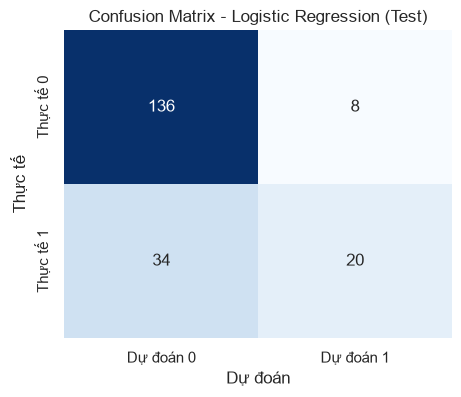

In [10]:
from sklearn.metrics import confusion_matrix

# Đánh giá 1 lần duy nhất trên tập Test
test_metrics = {
    selected_model_name: evaluate_pipeline(selected_pipeline, X_test, y_test),
    'Baseline': evaluate_pipeline(pipe_dummy, X_test, y_test)
}
df_test_results = pd.DataFrame(test_metrics).T
print("=== BẢNG ĐÁNH GIÁ TRÊN TẬP TEST ===")
print(df_test_results.round(4))

# Ma trận nhầm lẫn
cm = confusion_matrix(y_test, selected_pipeline.predict(X_test), labels=[0, 1])
df_cm = pd.DataFrame(cm, index=['Thực tế 0', 'Thực tế 1'], columns=['Dự đoán 0', 'Dự đoán 1'])

print("\n=== MA TRẬN NHẦM LẪN (CONFUSION MATRIX) ===")
print(df_cm)

# Trực quan hóa ma trận nhầm lẫn
plt.figure(figsize=(5, 4))
sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f"Confusion Matrix - {selected_model_name} (Test)")
plt.ylabel("Thực tế")
plt.xlabel("Dự đoán")
plt.show()


**Giải thích kết quả D1:**
- Trên tập Test, mô hình Logistic Regression đạt Accuracy 0.7879, Precision 0.7143, Recall 0.3704, F1 0.4878 và ROC AUC đạt 0.7900.
- Ma trận nhầm lẫn có tổng số quan sát là 198 hồ sơ, phân bố cụ thể: `TN = 136`, `FP = 8`, `FN = 34`, `TP = 20`.


### Câu D2

In [11]:
tn, fp, fn, tp = cm.ravel()
print(f"TN (True Negative) : {tn}")
print(f"FP (False Positive): {fp}")
print(f"FN (False Negative): {fn}")
print(f"TP (True Positive) : {tp}")

# Tính lại Precision và Recall bằng công thức thủ công
prec_manual = tp / (tp + fp)
rec_manual = tp / (tp + fn)

print(f"\nPrecision tính thủ công: {tp}/({tp}+{fp}) = {prec_manual:.4f}")
print(f"Precision từ thư viện  : {df_test_results.loc[selected_model_name, 'Precision']:.4f}")

print(f"Recall tính thủ công   : {tp}/({tp}+{fn}) = {rec_manual:.4f}")
print(f"Recall từ thư viện     : {df_test_results.loc[selected_model_name, 'Recall']:.4f}")

assert np.isclose(prec_manual, df_test_results.loc[selected_model_name, 'Precision']), "Precision không khớp!"
assert np.isclose(rec_manual, df_test_results.loc[selected_model_name, 'Recall']), "Recall không khớp!"
print("\n-> Kết quả tính thủ công đối chiếu hoàn toàn trùng khớp với thư viện!")


TN (True Negative) : 136
FP (False Positive): 8
FN (False Negative): 34
TP (True Positive) : 20

Precision tính thủ công: 20/(20+8) = 0.7143
Precision từ thư viện  : 0.7143
Recall tính thủ công   : 20/(20+34) = 0.3704
Recall từ thư viện     : 0.3704

-> Kết quả tính thủ công đối chiếu hoàn toàn trùng khớp với thư viện!


**Ý nghĩa nghiệp vụ D2:**
- **TN = 136:** Học viên thực tế tiếp tục học và mô hình dự báo đúng là tiếp tục học.
- **FP = 8 (Báo động nhầm / Gắn cờ nhầm):** Học viên thực tế tiếp tục học (nhãn 0) nhưng mô hình lại dự báo có nguy cơ ngừng học (nhãn 1). Hậu quả: trung tâm đào tạo tốn nguồn lực và nhân sự để liên hệ hỗ trợ một học viên vốn dĩ không có nguy cơ thôi học.
- **FN = 34 (Bỏ sót):** Học viên thực sự có nguy cơ ngừng học (nhãn 1) nhưng mô hình lại dự báo là bình thường (nhãn 0). Hậu quả: học viên không nhận được sự can thiệp và hỗ trợ kịp thời sau tuần 6, dẫn tới việc thôi học trong các tuần 7–10.
- **TP = 20:** Học viên thực sự có nguy cơ thôi học và mô hình phát hiện thành công để trung tâm đưa ra phương án can thiệp.
- **Đối chiếu:** Precision = $20 / (20 + 8) = 71.43\%$ và Recall = $20 / (20 + 34) = 37.04\%$, khớp tuyệt đối với kết quả thư viện.


### Câu D3
- **So với baseline:** Mô hình Logistic Regression mang lại giá trị thực tiễn vượt bậc: nâng `Recall` từ **0.00%** lên **37.04%** và nâng `ROC AUC` từ **0.5000** lên **0.7900**. Trong khi Baseline hoàn toàn vô dụng khi không nhận diện được bất kỳ ca có nguy cơ nào, thì Logistic Regression đã phát hiện được 20 trường hợp để can thiệp kịp thời.
- **Giải thích hiện tượng Accuracy cao nhưng Recall thấp:** Khi dữ liệu bị mất cân bằng (ở đây lớp 0 chiếm tới ~72.7%), một mô hình tầm thường chỉ cần luôn luôn đoán lớp 0 (như Baseline) vẫn dễ dàng đạt `Accuracy = 72.73%`. Nếu nhà quản lý chỉ nhìn vào độ chính xác tổng thể (Accuracy) sẽ bị ảo tưởng rằng mô hình hoạt động rất tốt, nhưng thực chất mô hình đã bỏ sót 100% học viên cần được giúp đỡ (`Recall = 0%`). Vì vậy trong bài toán này, `Recall`, `F1` và `ROC AUC` mới là các thước đo phản ánh đúng chất lượng phân loại.


### Câu D4
1. Tôi lựa chọn mô hình **Logistic Regression** vì đạt chỉ số ROC AUC trên tập Validation là 0.7496, vượt trội hơn so với Decision Tree (0.6180).
2. Khi kiểm thử độc lập trên tập Test, mô hình đạt ROC AUC 0.7900, độ chính xác (Accuracy) 78.79%, Precision 71.43% và Recall 37.04%.
3. Trong bối cảnh triển khai can thiệp, trung tâm chỉ phải chịu 8 ca báo động nhầm (FP = 8) giúp tối ưu hóa chi phí tư vấn, nhưng vẫn còn 34 học viên thực sự có nguy cơ bị bỏ sót (FN = 34) chưa được tiếp cận.
4. Do tập dữ liệu mô phỏng còn hạn chế về số lượng thuộc tính và chưa bao hàm các yếu tố ngoại cảnh thực tế (như tài chính, việc làm), hiệu quả thực tế cần được kiểm nghiệm cẩn trọng.
5. Để nâng cao số lượng học viên được cứu trợ, trung tâm có thể hạ ngưỡng phân loại xác suất (threshold < 0.5) dựa trên ma trận chi phí tối ưu trên tập Validation nhằm đánh đổi thêm một ít FP để giảm mạnh FN.
6. **Tuyệt đối không được sử dụng tập Test để tinh chỉnh mô hình**, vì tập Test đóng vai trò là mẫu kiểm thử mù đại diện cho tương lai; việc can thiệp vào Test sẽ làm mất tính độc lập khách quan và gây rò rỉ dữ liệu (data leakage).
